# Лабораторная работа 5

Выявление и разрешение конфликтов в расписании.

**Цель:** обнаруживать пересечения, предлагать вытеснение более дешевых заказов и корректно перепланировать уступающих. Выполнены все три задания самостоятельной работы.

Запускайте ячейки сверху вниз. Полный код и данные находятся в notebook; отдельные `.py` не нужны. Зависимости: `pip install thespian openpyxl`. Старые notebooks сохранены.

В исходном проекте нет эталонного конфликтного Excel и коммита 2e6813e. Поэтому создан собственный сценарий с одним Лермонтовым М. Ю. и скоростью 5. Числа 129,45 и 108,65 относятся к данным эталона и здесь не воспроизводятся; результаты собственного сценария не выдаются за эталонные.

## 1 Исходные данные

Excel содержит три заказа и одного курьера. Заказ 3 «Доставка документов» поступает последним и стоит дороже первых двух. У курьера скорость 5 и ставка 5 за единицу времени. Веса: время получения 0,2, доставки 0,3, стоимость 0,5. Дополнительный критерий из ЛР4 сохранен, но его вес равен нулю. Встроенные файлы создаются, только если их нет рядом.

In [1]:
from pathlib import Path
import base64
import json
import logging

Path('Отчёты').mkdir(exist_ok=True)
input_bytes = base64.b64decode('UEsDBBQAAAAIAPx7ZF1Gx01IlQAAAM0AAAAQAAAAZG9jUHJvcHMvYXBwLnhtbE3PTQvCMAwG4L9SdreZih6kDkQ9ip68zy51hbYpbYT67+0EP255ecgboi6JIia2mEXxLuRtMzLHDUDWI/o+y8qhiqHke64x3YGMsRoPpB8eA8OibdeAhTEMOMzit7Dp1C5GZ3XPlkJ3sjpRJsPiWDQ6sScfq9wcChDneiU+ixNLOZcrBf+LU8sVU57mym/8ZAW/B7oXUEsDBBQAAAAIAPx7ZF2imXm+7wAAACsCAAARAAAAZG9jUHJvcHMvY29yZS54bWzNklFLwzAQx7+K5L29ptUJocuLY08KggPFt5DctmCThuSk3bc3rVuH6AfwMXf//O53cK0OQvcRn2MfMJLFdDO6ziehw5odiYIASPqITqUyJ3xu7vvoFOVnPEBQ+kMdEOqqWoFDUkaRgglYhIXIZGu00BEV9fGMN3rBh8/YzTCjATt06CkBLzkwOU0Mp7Fr4QqYYITRpe8CmoU4V//Ezh1g5+SY7JIahqEcmjmXd+Dw9vT4Mq9bWJ9IeY35V7KCTgHX7DL5tXnY7LZM1lW9Kjgvqtsd56Lh4u7+fXL94XcVdr2xe/uPjS+CsoVfdyG/AFBLAwQUAAAACAD8e2Rd+lwBWfwCAADaDQAAEwAAAHhsL3RoZW1lL3RoZW1lMS54bWy1V9lS2zAU/RWP34u8LxkCw5K0D+20U/gBxZaXIsseSyHw95UVL7IdhbAkzIAlnXPPse7VVbi8fimw9oxqmpdkqZsXhq4hEpVxTtKlvmXJt0C/vrqEC5ahAmkEFmip32WQff/zqGucS+gCLvWMsWoBAI04CtKLskKEryVlXUDGh3UK4hrueMwCA8swPFDAnOh93BXmvwijzUSE64fogFizFj+ZzR/6Su9wrT1DvNR50LjcPaIXpmsYUsYXlrohProGri5Bz8JMQZaIa/HpiC0jfrIEsU43PdNYWYFjDgrWXmEOXAXNzxBRIGAU8dc1Z2DT9YzA6sASav94IHrom/aEICnYc4XQu7WcMcEeCM78Rdfh6t4dE5yB4M4IN4Z1G9pjgjsQvBnBWd341mpMEKgM5+RpDvf8IPA6eI9JSvzjID70PMO/7/ADDEiltg9A2KjwfidJHiFRdwX8V9ZrDhBZhiwnGnutUAKjpkAhzjd1rv3M04wJHbhA8A1ARI8CwESzyMmbBo5IHxHt5QYFIG+G2JqCKY9kkmP8wF4x+kmFOVriPF7zSTEQrD4VVcYfO8ERMK3h8EzbUCnVqpLyEtSVsUQHyQnbz3l+d+r5Jm2LX2XcFr1pDAsUsmHBcKU+0SuIUUplD66IcKIP31b4GOSmPuwTfZjGe4wE5ruNhEeNACk9/BhpsLklXKdttzSCGMVNwtoAo7R+SYpDR/VG1me39oQU0wzGqItrqJyois00vjDJkhU/OOwkDBVGrONGPpxkMG8HmIxH2q7R97u3+1CzqGrK7iHN9jix1N+vRJIJeZWfX8ZqduZ8MmC6hyhJUMQUM8OQr7VRDi5/Ft0Myi1D9UMW77QN3tZ/IS8K1zf5nmtxTlmXAD6oh/KZf78Y5iGuMth28tGh3ePFc68pmRV2ptbBoZ3apOsvua7eZk26lqrd+uqTeIb7MZTuJal/hIr+oe6p7qmd7F3XpuxDtqdstLbCnn2mRuupBM/YUKclC6SvY2I0+Qeqm7n6D1BLAwQUAAAACAD8e2RdvfvtFlcDAABzEQAAGAAAAHhsL3dvcmtzaGVldHMvc2hlZXQxLnhtbNVYW2/aMBT+K1Em7bG5k6QFpJVCgTKparXtOQUDUZOYJaa0/76242R2ZlyvRdP2gi/H3/Hncz5fQv8Ay8dqCwAynvOsqAbmFqHduWVVyy3Ik+oM7kCBLWtY5gnCzXJjVbsSJCsKyjPLte2elSdpYQ77tO+2HPbhHmVpAW5Lo9rneVK+XIIMHgamYzYdd+lmi0iHNezvkg24B+jb7rbELav1skpzUFQpLIwSrAfmF+d84ZPxdMD3FBwqrm6QlTxA+Egas9XAtAkhkIElIh4SXDyBEcgy4gjT+Ml8mu2UBMjXG+8Tuna8loekAiOY/UhXaDswI9NYgXWyz9AdPEwBW09A/C1hVtFf41CPdfDg5b5CMGdgzCBPi7pMnlkcOIDrHgG4DOB2AEdn8BjA0wX4DODrAgIGCHQBPQbo6QJCBgh1AREDRLqAmAFiXYBjN5mztSFtsrvZPg5p0u3QfFu1sKgqrxKUDPslPBglHU/U1+s1flo94k2wJCOo5mmucG9akN15j0psTbFDNPz8ybED74IUUa8ufFqEYd2KLvoWwgzIcGvJnF5qOw3d2o0t8x3w84a+AAh4HAZIWIw0WLiC05gvcKfE6ZWGU8a0XmEcCWvyZU7HGk5rfGwLuRDC1nTG3EjHtmUTTjQmFGfqNemmixGnD/ggMoa4ZVBjKOBZTJy6CGTpZry9C+NZwvz6v2D+ImE+/WvMQxEfd8Zwuylqt5802LN/m7IsyvO3KfuuQLLdmE3yPpp8aox56pFwzISq8+XmNPzfFc8PEV9oaCUS9BC+f0YL32/tJefWl5znHr/kXMqKPEWfhk7feuLvKlfFOJCFMeZF8Yuw4cguIcXUVwrbWLDZtmid8NaO7Vphm4peReNMAZwrqN7wNrcDXJwsvAoFeG8rwOM5dhTgnUwBrkwBnkIBCtvYU4R14ikSee0pFKDyOlMA57zN6yhAxWZxsvAqFOC/rQD/OP9LX3XcHn9dyY/SI3eay98h0peu+LgLpU/Fka9Qk8I2Fpb/23niK84ThW3qq84TBXDO24KOmnhb2BHTH2RKO+BYbzJpWdz3FPkr4mtSbtKiMjKwxhTsM/z1WdYio3UEd7SGb8AHiLAEm9YWJCtQkhbeCWsIUdMgX27t/yzDV1BLAwQUAAAACAD8e2Rdm6xyXzwDAABnDQAAGAAAAHhsL3dvcmtzaGVldHMvc2hlZXQyLnhtbOVX226jMBD9FYuV9jEYMLfmIm3vrVSparW7zzRxElTAWeM07d+vbQy1qUnY533JMNhnfM54xiazA6Gv9RZjBt7Loqrnzpax3Znr1sstLrN6Qna44iNrQsuMcZdu3HpHcbaSoLJwfQgjt8zyylnM5LtHupiRPSvyCj9SUO/LMqMf57ggh7njOe2Lp3yzZeKFu5jtsg1+xuzn7pFyz+2irPISV3VOKkDxeu788M7ufTFfTviV40OtPQOh5IWQV+HcreYOFIRwgZdMRMi4ecMXuChEIE7jj4rpdEsKoP7cRr+W2rmWl6zGF6T4na/Ydu4kDljhdbYv2BM53GKlJxTxlqSo5S84NHM9Pnm5rxkpFZgzKPOqsdm7yoMG8P0BgK8Afg8wuEKgAMFYAFIA1AMEcAAQKkDY14AGAJECRH1ANACIFSAeqyFRgGQsIFWAdCzAg+3OQVlBzZbLernMWLaYUXIAVM4XdRF10rpK4eW5FDNkNcos8rd5JfrmmVE+mvOAbPH9mwfDZCpM7DcmaEwsTSI9D8LGC6VJ08bzpkB7m0SNQQY+mc5cxhWI5dylInV+mlTUrIgabiGyhbkYoQ0a3KKWlKSoPEObykIKWw9YBg3PmiK1Utx5TZjYoBEYUxMjb6HGzYPBFLxbEnD5PyXgw5KAq9HV3YqM2woGegaUSXvSpUGGSLM7kN4PaaCCpkZ2fCNaaki2lvX1CFGxzjQx9xENahJ7BDRRn8R1UtHAzgO9dIzDQiEVndSzqboZ0fO+pQL+ZeG0vwFAi2etduWlqGWupycxKxJZ2HG8Revt6B1U1WH25dDWWVa6G7ES0jOW9jVZktse86h9aVn4/vTCKNBF8dx+bQDzPFA79IXi12PlRGpcfj12d6Tf3JGBP3xH+lKF+MZ8W3gz902/qvxjqfUMpomt/0JLp8Yq7aE/nTQFB6cT2wWnE4MmscsjY1dHSVszmRoncndmSYtMRb6+n9au+OxH2/F2hPiNPhaaY7dHxu6MHewFvR8YNKokOFYlxkx0eqarfamJvx8PGd3kVQ0KvObz4IR/cdIGI58Z2ckn3kwvhPGIrbfl/4QwFR6ntyaEtY74Juz+Wy3+AlBLAwQUAAAACAD8e2Rd1s9qynACAADPDAAADQAAAHhsL3N0eWxlcy54bWzdV9uOmzAQ/RWLDyhJUFGoAGmLGqkvVaXdh746wRBLxqbGSUm/vh6bXNezyvalUUGRPT4+M+O5GCUfzEGw5y1jhoydkEMRbY3pP8XxsNmyjg4fVM+kRRqlO2qsqNt46DWj9QCkTsSL2SyNO8plVOZy1606M5CN2klTRLMoLvNGyfNKEvkFu5V2jOypKKKKasGNgr3Db780n4MU+523+580p+L9u9fTZpTphsFq4EJcO2wXyrynxjAtV1ZwHLf4CiLT/OXQsyJqNT3MFx+juwmDErwGk22lhNJEt+siWq2+pPA6NRfUk1I3WM/XStdMn3yfR8elMhesMZauebuF0ageQqKMUZ2d1Jy2SlJ3sCNjmli1GybEM9TJj+ZK99gQn/CvNeSaQPyOU+vQNPVqvAD6L7V53Rdq079SS3q+V+bzzp5GOvnnThn2XbOGj04em5N9TPv8X2mnfS8OT4K3smM+sncbLHN65JE904ZvoKg3VmTaxXpsHsol8kvT/oWNZmrDe/1bPKJ/iwfxL55a6KJPr7r0tErgUiyib3CTi6uqPfckaIGLx45c1mxkdTWJ9ia6uJJm0wPsW2TlnjCCcTwWRgDD7GAeYBzPwuz8T+dZoufxGObbMogsUc4S5XhWCKnci9kJczL7hE+aZUmSplhEqyroQYXFLU3hF9aG+QYMzA5Yel+s8WzjFfJ2HWA5fatCsJPilYidFI81IOG4ASPLwtnG7AADywJWO2A/bAdqKsxJEsgq5hvWwTiSZRgCtRiu0TRFopPCG84P1iVJkmVhBLCwB0mCIdCNOIJ5AD5gSJK4b9TN9yg+fqfi81+Y8g9QSwMEFAAAAAgA/HtkXZeKuxzAAAAAEwIAAAsAAABfcmVscy8ucmVsc52SuW7DMAxAf8XQnjAH0CGIM2XxFgT5AVaiD9gSBYpFnb+v2qVxkAsZeT08EtweaUDtOKS2i6kY/RBSaVrVuAFItiWPac6RQq7ULB41h9JARNtjQ7BaLD5ALhlmt71kFqdzpFeIXNedpT3bL09Bb4CvOkxxQmlISzMO8M3SfzL38ww1ReVKI5VbGnjT5f524EnRoSJYFppFydOiHaV/Hcf2kNPpr2MitHpb6PlxaFQKjtxjJYxxYrT+NYLJD+x+AFBLAwQUAAAACAD8e2RdWSpU99QAAACqAQAADwAAAHhsL3dvcmtib29rLnhtbLVQOwrCQBC9StgDuJrCIiSpbGzEK6zZiVmS3Q0z66cULLUXPIWNCJ4iuZEbNWAlNhbzfcObx4s3FsuFtWWw1ZWhhBXO1RHnlBWgBQ1sDcYjuUUtnB9xyalGEJIKAKcrHg6HY66FMiyNe6458jR+HtC7vtgj/IXf5rnKYGKzlQbjXg8QKuGUNVSomlhghIaENafm0tx93NoDC55/pjJhI9874fzBWpFaVMACjJQHcCpHjP9V0bndt7v22Fx9/tQUftEUdpp4b5eEXBmQM89H3b73NH0AUEsDBBQAAAAIAPx7ZF2N9yxatAAAAIkCAAAaAAAAeGwvX3JlbHMvd29ya2Jvb2sueG1sLnJlbHPFkk0KgzAQRq8ScoCO2tJFUVfduC1eIOj4g9GEzJTq7Wt1oYEuupGuwjch73swiR+oFbdmoKa1JMZeD5TIhtneAKhosFd0MhaH+aYyrlc8R1eDVUWnaoQoCK7g9gyZxnumyCeLvxBNVbUF3k3x7HHgL2B4GddRg8hS5MrVyImEUW9jguUITzNZiqxMpMvKUMK/hSJPKDpQiHjSSJvNmr3684H1PL/FrX2J69DfyeXjAN7PS99QSwMEFAAAAAgA/HtkXW6nJLweAQAAVwQAABMAAABbQ29udGVudF9UeXBlc10ueG1sxZTPTsMwDMZfpcp1ajJ24IDWXYAr7MALhNZdo+afYm90b4/bbpNAo2IqEpdGje3v5/iLsn47RsCsc9ZjIRqi+KAUlg04jTJE8BypQ3Ka+DftVNRlq3egVsvlvSqDJ/CUU68hNusnqPXeUvbc8Taa4AuRwKLIHsfEnlUIHaM1pSaOq4OvvlHyE0Fy5ZCDjYm44AShrhL6yM+AU93rAVIyFWRbnehFO85SnVVIRwsopyWu9Bjq2pRQhXLvuERiTKArbADIWTmKLqbJxBOG8Xs3mz/ITAE5c5tCRHYswe24syV9dR5ZCBKZ6SNeiCw9+3zQu11B9Us2j/cjpHbwA9WwzJ/xV48v+jf2sfrHPt5DaP/6qverdNr4M18N78nmE1BLAQIUAxQAAAAIAPx7ZF1Gx01IlQAAAM0AAAAQAAAAAAAAAAAAAACAAQAAAABkb2NQcm9wcy9hcHAueG1sUEsBAhQDFAAAAAgA/HtkXaKZeb7vAAAAKwIAABEAAAAAAAAAAAAAAIABwwAAAGRvY1Byb3BzL2NvcmUueG1sUEsBAhQDFAAAAAgA/HtkXfpcAVn8AgAA2g0AABMAAAAAAAAAAAAAAIAB4QEAAHhsL3RoZW1lL3RoZW1lMS54bWxQSwECFAMUAAAACAD8e2RdvfvtFlcDAABzEQAAGAAAAAAAAAAAAAAAgIEOBQAAeGwvd29ya3NoZWV0cy9zaGVldDEueG1sUEsBAhQDFAAAAAgA/HtkXZuscl88AwAAZw0AABgAAAAAAAAAAAAAAICBmwgAAHhsL3dvcmtzaGVldHMvc2hlZXQyLnhtbFBLAQIUAxQAAAAIAPx7ZF3Wz2rKcAIAAM8MAAANAAAAAAAAAAAAAACAAQ0MAAB4bC9zdHlsZXMueG1sUEsBAhQDFAAAAAgA/HtkXZeKuxzAAAAAEwIAAAsAAAAAAAAAAAAAAIABqA4AAF9yZWxzLy5yZWxzUEsBAhQDFAAAAAgA/HtkXVkqVPfUAAAAqgEAAA8AAAAAAAAAAAAAAIABkQ8AAHhsL3dvcmtib29rLnhtbFBLAQIUAxQAAAAIAPx7ZF2N9yxatAAAAIkCAAAaAAAAAAAAAAAAAACAAZIQAAB4bC9fcmVscy93b3JrYm9vay54bWwucmVsc1BLAQIUAxQAAAAIAPx7ZF1upyS8HgEAAFcEAAATAAAAAAAAAAAAAACAAX4RAABbQ29udGVudF9UeXBlc10ueG1sUEsFBgAAAAAKAAoAhAIAAM0SAAAAAA==')
if not Path('Исходные данные_конфликт.xlsx').exists():
    Path('Исходные данные_конфликт.xlsx').write_bytes(input_bytes)
config_text = '{\n  "default_profile": "ЛР5",\n  "criteria": [\n    {\n      "name": "start_efficiency",\n      "field": "pickup",\n      "direction": "decreasing"\n    },\n    {\n      "name": "finish_efficiency",\n      "field": "time_to",\n      "direction": "decreasing"\n    },\n    {\n      "name": "price_efficiency",\n      "field": "price",\n      "direction": "decreasing"\n    },\n    {\n      "name": "pickup_accuracy_efficiency",\n      "field": "pickup_deviation",\n      "direction": "decreasing"\n    }\n  ],\n  "profiles": {\n    "ЛР5": {\n      "start_efficiency": 0.2,\n      "finish_efficiency": 0.3,\n      "price_efficiency": 0.5,\n      "pickup_accuracy_efficiency": 0\n    }\n  }\n}\n'
if not Path('planning_config.json').exists():
    Path('planning_config.json').write_text(config_text, encoding='utf-8')
logging.basicConfig(level=logging.INFO, format='%(message)s', force=True,
                    handlers=[logging.FileHandler('output_lab5.txt', encoding='utf-8', mode='w')])


In [2]:
from openpyxl import load_workbook


def get_excel_data(filename, sheet_name):
    workbook = load_workbook(filename, read_only=True, data_only=True)
    try:
        rows = workbook[sheet_name].iter_rows(values_only=True)
        columns = next(rows)
        return [dict(zip(columns, row)) for row in rows if any(v is not None for v in row)]
    finally:
        workbook.close()

import json
import math


def load_planning_config(filename='planning_config.json', profile=None):
    with open(filename, encoding='utf-8') as file:
        config = json.load(file)
    profile = profile or config['default_profile']
    weights = config['profiles'][profile]
    criteria = [{**item, 'weight': weights[item['name']]} for item in config['criteria']]
    if not criteria or len({c['name'] for c in criteria}) != len(criteria):
        raise ValueError('Критерии должны быть непустыми и иметь уникальные имена')
    if any(c['direction'] not in ('increasing', 'decreasing') for c in criteria):
        raise ValueError('Неизвестное направление нормировки')
    if any(not math.isfinite(c['weight']) or c['weight'] < 0 for c in criteria):
        raise ValueError('Веса должны быть конечными неотрицательными числами')
    if not math.isclose(sum(c['weight'] for c in criteria), 1.0, abs_tol=1e-9):
        raise ValueError('Сумма весов должна быть равна единице')
    return profile, criteria


In [3]:
order_data = get_excel_data('Исходные данные_конфликт.xlsx', 'Заказы')
courier_data = get_excel_data('Исходные данные_конфликт.xlsx', 'Курьеры')
for row in order_data + courier_data:
    print(row)


{'Номер': 1, 'Наименование': 'Посылка 1', 'Масса': 1, 'Объем': 1, 'Стоимость': 100, 'Координата получения x': 0, 'Координата получения y': 0, 'Координата доставки x': 10, 'Координата доставки y': 0, 'Время получения заказа': 1, 'Время доставки заказа': 20, 'Тип заказа': 'Посылка'}
{'Номер': 2, 'Наименование': 'Посылка 2', 'Масса': 1, 'Объем': 1, 'Стоимость': 20, 'Координата получения x': 10, 'Координата получения y': 0, 'Координата доставки x': 20, 'Координата доставки y': 0, 'Время получения заказа': 3, 'Время доставки заказа': 10, 'Тип заказа': 'Посылка'}
{'Номер': 3, 'Наименование': 'Доставка документов', 'Масса': 1, 'Объем': 1, 'Стоимость': 300, 'Координата получения x': 0, 'Координата получения y': 0, 'Координата доставки x': 10, 'Координата доставки y': 0, 'Время получения заказа': 5, 'Время доставки заказа': 7, 'Тип заказа': 'Документы'}
{'Табельный номер': 1, 'ФИО': 'Лермонтов М. Ю.', 'Координата начального положения x': 0, 'Координата начального положения y': 0, 'Типы доставля

## 2 Сообщения и сущности

Сохранен каркас ЛР4. Добавлены REMOVE_ORDER, CONSENT_REQUEST и CONSENT_RESPONSE. Сцена хранит сущности, адресная книга сопоставляет их адресам агентов.

**message.py**

In [4]:
"""Сообщения протокола планирования ЛР5."""

from dataclasses import dataclass
from enum import Enum
from typing import Any


class MessageType(Enum):
    REMOVE_ORDER = 'Удаление заказа'
    CONSENT_REQUEST = 'Запрос согласия'
    CONSENT_RESPONSE = 'Ответ о согласии'
    INIT_MESSAGE = 'Инициализация'
    PRICE_REQUEST = 'Запрос параметров'
    PRICE_RESPONSE = 'Ответ с параметрами'
    PLANNING_REQUEST = 'Запрос планирования'
    PLANNING_RESPONSE = 'Результат планирования'


@dataclass
class Message:
    msg_type: MessageType
    msg_body: Any = None


**point.py**

In [5]:
"""Точка и евклидово расстояние."""

import math
from dataclasses import dataclass


@dataclass
class Point:
    x: float
    y: float

    def __repr__(self):
        return f'({self.x:g}; {self.y:g})'

    def get_distance_to_other(self, other_point):
        return math.dist((self.x, self.y), (other_point.x, other_point.y))


**scene.py**

In [6]:
"""Сцена сущностей виртуального мира."""

from collections import defaultdict


class Scene:
    def __init__(self):
        self.entities = defaultdict(list)

    def get_entities_by_type(self, entity_type):
        return self.entities.get(entity_type, [])


**entities/base_entity.py**

In [7]:
class BaseEntity:
    def __init__(self, onto_desc, scene=None):
        self.onto_description = onto_desc
        self.name = onto_desc.get('data', {}).get('label', {}).get('value')
        self.uri = 'UNKNOWN_URI'
        self.scene = scene


**entities/order_entity.py**

In [8]:
class OrderEntity(BaseEntity):
    def __init__(self, onto_desc, init_dict_data, scene=None):
        super().__init__(onto_desc, scene)
        self.number = init_dict_data['Номер']
        self.name = init_dict_data['Наименование']
        self.weight = float(init_dict_data['Масса'])
        self.volume = float(init_dict_data['Объем'])
        self.price = float(init_dict_data['Стоимость'])
        self.point_from = Point(float(init_dict_data['Координата получения x']),
                                float(init_dict_data['Координата получения y']))
        self.point_to = Point(float(init_dict_data['Координата доставки x']),
                              float(init_dict_data['Координата доставки y']))
        self.time_from = float(init_dict_data['Время получения заказа'])
        self.time_to = float(init_dict_data['Время доставки заказа'])
        self.order_type = init_dict_data['Тип заказа']
        self.uri = 'Order' + str(self.number)
        self.assigned_courier = None
        self.selected_variant = None

    def get_type(self):
        return 'ORDER'


**schedule_item.py**

In [9]:
from dataclasses import dataclass



@dataclass
class ScheduleItem:
    order: OrderEntity
    rec_type: str
    start_time: float
    end_time: float
    point_from: Point
    point_to: Point
    cost: float
    all_params: dict


**reference_book.py**

In [10]:
import logging


class ReferenceBook:
    def __init__(self):
        self.agents_entities = {}

    def add_agent(self, entity, agent_address):
        self.agents_entities[entity] = agent_address

    def get_address(self, entity):
        address = self.agents_entities.get(entity)
        if address is None:
            logging.error('Агент %s отсутствует в адресной книге', entity.uri)
        return address


**agent_base.py**

In [11]:
"""Базовый агент: подписки, диспетчеризация и инициализация."""

import logging

from thespian.actors import Actor



class AgentBase(Actor):
    def __init__(self):
        self.name = type(self).__name__
        self.handlers = {}
        self.subscribe(MessageType.INIT_MESSAGE, self.handle_init_message)

    def subscribe(self, msg_type, handler):
        self.handlers[msg_type] = handler

    def receiveMessage(self, message, sender):
        if not isinstance(message, Message):
            return
        handler = self.handlers.get(message.msg_type)
        if handler is None:
            logging.warning('%s: нет обработчика %s', self.name, message.msg_type)
            return
        logging.info('%s <- %s: %s', self.name, sender, message.msg_type.value)
        try:
            handler(message, sender)
        except Exception:
            logging.exception('Ошибка обработки сообщения агентом %s', self.name)
            raise

    def handle_init_message(self, message, sender):
        self.scene = message.msg_body['scene']
        self.dispatcher = message.msg_body['dispatcher']
        self.entity = message.msg_body['entity']
        self.name += ' ' + self.entity.name

    def send(self, target, message):
        self.dispatcher.message_counts[message.msg_type.value] += 1
        super().send(target, message)

    @staticmethod
    def get_decreasing_kpi_value(value, min_value, max_value):
        if max_value == min_value:
            return 1
        if value > max_value or value < min_value:
            return -1
        if abs(value - min_value) < 0.000001:
            return 1
        if abs(value - max_value) < 0.000001:
            return 0
        return 1 - (value - min_value) / (max_value - min_value)

    @staticmethod
    def get_increasing_kpi_value(value, min_value, max_value):
        if max_value == min_value:
            return 1
        if value > max_value or value < min_value:
            return -1
        if abs(value - min_value) < 0.000001:
            return 0
        if abs(value - max_value) < 0.000001:
            return 1
        return (value - min_value) / (max_value - min_value)


## 3 Выявление конфликтов и варианты

get_conflicts использует полуоткрытые интервалы: соприкосновение границ не является конфликтом. Ожидание и нулевые интервалы исключены. get_all_order_records возвращает все записи одного заказа. Сводка конфликта включает начало, конец и сумму стоимости **всех** его записей.

Для conflict выбирается самый дешевый из пересекающихся заказов с ценой меньше цены нового заказа. Движение начинается из точки и времени первой записи вытесняемого. При включенном `multiple=True` предлагается также удаление всей группы, если все ее заказы дешевле нового. Другие заказы нельзя задевать. Проверяется и пространственная непрерывность маршрута; варианты, требующие изменения соседних неуступающих маршрутов, отклоняются.

**entities/courier_entity.py**

In [12]:
import logging
import math



class CourierEntity(BaseEntity):
    def __init__(self, onto_desc, init_dict_data, scene=None):
        super().__init__(onto_desc, scene)
        self.number = init_dict_data['Табельный номер']
        self.name = init_dict_data['ФИО']
        self.point = Point(float(init_dict_data['Координата начального положения x']),
                           float(init_dict_data['Координата начального положения y']))
        self.types = [s.strip() for s in init_dict_data['Типы доставляемых заказов'].split(';')]
        self.start_cost = float(init_dict_data['Стоимость выхода на работу'])
        self.rate = float(init_dict_data['Цена работы за единицу времени'])
        self.velocity = float(init_dict_data['Скорость'])
        self.max_volume = float(init_dict_data['Объем ранца'])
        self.max_mass = float(init_dict_data['Грузоподъемность'])
        self.schedule = []
        self.uri = 'Courier' + str(self.number)

    def get_type(self):
        return 'COURIER'

    def get_last_point(self):
        return self.schedule[-1].point_to if self.schedule else self.point

    def get_last_time(self):
        return self.schedule[-1].end_time if self.schedule else 0.0

    def get_all_order_records(self, order, schedule=None):
        schedule = self.schedule if schedule is None else schedule
        return [item for item in schedule if item.order is order]

    def get_conflicts(self, start_time, end_time, schedule=None):
        schedule = self.schedule if schedule is None else schedule
        if start_time >= end_time:
            return []
        return [item for item in schedule if item.rec_type != 'Ожидание'
                and item.start_time < item.end_time
                and item.start_time < end_time and start_time < item.end_time]

    def get_conflicted_tasks(self, records, schedule=None):
        tasks = {}
        for record in records:
            if record.order in tasks:
                continue
            items = self.get_all_order_records(record.order, schedule)
            tasks[record.order] = {'start': min(i.start_time for i in items),
                                   'end': max(i.end_time for i in items),
                                   'cost': sum(i.cost for i in items)}
        return tasks

    def make_variant(self, order, start, point, name, removed=()):
        to_order = point.get_distance_to_other(order.point_from) / self.velocity
        with_order = order.point_from.get_distance_to_other(order.point_to) / self.velocity
        pickup = start + to_order
        return {'courier': self, 'order': order, 'time_from': start,
                'time_to': pickup + with_order, 'arrival': pickup, 'pickup': pickup,
                'price': (to_order + with_order) * self.rate, 'point_from': point,
                'variant_name': name, 'pickup_deviation': abs(pickup - order.time_from),
                'removed_orders': tuple(removed)}

    def records_for(self, variant):
        order = variant['order']
        start, pickup, end = (variant[k] for k in ('time_from', 'pickup', 'time_to'))
        return [ScheduleItem(order, 'Движение за грузом', start, pickup,
                             variant['point_from'], order.point_from, (pickup-start)*self.rate, variant),
                ScheduleItem(order, 'Ожидание', pickup, pickup,
                             order.point_from, order.point_from, 0.0, variant),
                ScheduleItem(order, 'Движение с грузом', pickup, end,
                             order.point_from, order.point_to, (end-pickup)*self.rate, variant)]

    def preview(self, variant, schedule):
        removed = variant['removed_orders']
        remaining = [r for r in schedule if r.order not in removed]
        if self.get_conflicts(variant['time_from'], variant['time_to'], remaining):
            return None
        result = sorted(remaining + self.records_for(variant), key=lambda r: r.start_time)
        # Проверяем также координаты: отсутствие пересечений само по себе недостаточно.
        point, time = self.point, 0.0
        for item in result:
            if item.start_time < time - 1e-9 or item.point_from != point:
                return None
            point, time = item.point_to, item.end_time
        return result

    def get_variants(self, order, schedule=None, conflicts=False, multiple=True, ancestors=()):
        schedule = self.schedule if schedule is None else schedule
        if (order.order_type not in self.types or order.weight > self.max_mass
                or order.volume > self.max_volume or self.velocity <= 0):
            return []
        last_point = schedule[-1].point_to if schedule else self.point
        last_time = schedule[-1].end_time if schedule else 0.0
        variants = [self.make_variant(order, last_time, last_point, 'asap')]
        time_to_order = last_point.get_distance_to_other(order.point_from) / self.velocity
        jit_start = order.time_from - time_to_order
        jit = self.make_variant(order, jit_start, last_point, 'jit_pickup')
        if jit_start > 0 and self.preview(jit, schedule) is not None:
            variants.append(jit)
        if not schedule:
            duration = variants[0]['time_to'] - variants[0]['time_from']
            departure = order.time_to - duration
            if departure > 0:
                variants.append(self.make_variant(order, departure, last_point, 'jit_delivery'))
        if not conflicts or jit_start <= 0:
            return variants
        records = self.get_conflicts(jit_start, jit['time_to'], schedule)
        tasks = self.get_conflicted_tasks(records, schedule)
        logging.info('%s: конфликтующие заказы %s', self.name,
                     {o.number: summary for o, summary in tasks.items()})
        cheaper = sorted((o for o in tasks if o.price < order.price and o not in ancestors),
                         key=lambda o: (o.price, str(o.number)))
        if not cheaper:
            return variants
        groups = [(cheaper[0],)]
        if multiple and len(cheaper) > 1 and len(cheaper) == len(tasks):
            groups.append(tuple(cheaper))
        for removed in groups:
            first = min((r for o in removed for r in self.get_all_order_records(o, schedule)),
                        key=lambda r: r.start_time)
            variant = self.make_variant(order, first.start_time, first.point_from, 'conflict', removed)
            if self.preview(variant, schedule) is not None:
                logging.info('%s: вариант conflict, вытеснение %s', self.name, [o.number for o in removed])
                variants.append(variant)
        return variants

    def add_order_to_schedule(self, order, start_time, end_time, price, params):
        result = self.preview(params, self.schedule)
        if result is None:
            return False
        self.schedule = result
        return True


## 4 Копия расписания и откат

PlanningTransaction хранит копии расписаний всех курьеров, новые назначения и перечень вытеснений. Вставки и рекурсивные переезды выполняются только в черновике. До общего согласия реальное место уступающего сохраняется. При отказе восстанавливается состояние перед попыткой, включая назначения и другие курьерские расписания. Удаляются все записи уступающего заказа, а не только пересекающиеся.

**transaction.py**

In [13]:
"""Черновики расписаний: принятие всех перестановок или полный откат."""


class PlanningTransaction:
    def __init__(self, scene):
        self.schedules = {c: list(c.schedule) for c in scene.get_entities_by_type('COURIER')}
        self.placements = {}
        self.evicted = []

    def snapshot(self):
        return ({c: list(s) for c, s in self.schedules.items()},
                dict(self.placements), list(self.evicted))

    def restore(self, snapshot):
        self.schedules, self.placements, self.evicted = snapshot

    def commit(self):
        for courier, schedule in self.schedules.items():
            courier.schedule = schedule
        for order, variant in self.placements.items():
            order.assigned_courier = variant['courier']
            order.selected_variant = variant


**courier_agent.py**

In [14]:
import logging
import math



class CourierAgent(AgentBase):
    def __init__(self):
        super().__init__()
        self.subscribe(MessageType.PRICE_REQUEST, self.handle_price_request)
        self.subscribe(MessageType.PLANNING_REQUEST, self.handle_planning_request)

    def handle_price_request(self, message, sender):
        body = message.msg_body
        context = body.get('context')
        schedule = context.schedules[self.entity] if context else self.entity.schedule
        variants = self.entity.get_variants(body['order'], schedule,
                                            self.dispatcher.enable_conflicts,
                                            self.dispatcher.multiple,
                                            body.get('ancestors', ()))
        self.send(sender, Message(MessageType.PRICE_RESPONSE, variants))

    def add_order(self, params, context):
        schedule = context.schedules[self.entity]
        # Сохраняем весь черновик, включая записи других курьеров.
        old_state = context.snapshot()
        variants = self.entity.get_variants(params['order'], schedule,
                                            self.dispatcher.enable_conflicts,
                                            self.dispatcher.multiple)
        current = next((v for v in variants if v['variant_name'] == params['variant_name']
                        and v['removed_orders'] == params['removed_orders']
                        and v['point_from'] == params['point_from']
                        and all(math.isclose(v[k], params[k], abs_tol=1e-9)
                                for k in ('time_from', 'time_to', 'price'))), None)
        if current is None:
            return False
        result = self.entity.preview(params, schedule)
        if result is None:
            context.restore(old_state)
            return False
        context.schedules[self.entity] = result
        context.placements[params['order']] = params
        for victim in params['removed_orders']:
            context.evicted.append((victim, self.entity))
        logging.info('%s: размещен %s для заказа %s; вытеснение %s', self.name,
                     params['variant_name'], params['order'].number,
                     [o.number for o in params['removed_orders']])
        return True

    def handle_planning_request(self, message, sender):
        body = message.msg_body
        accepted = self.add_order(body['variant'], body['context'])
        self.send(sender, Message(MessageType.PLANNING_RESPONSE, accepted))


## 5 Согласие и рекурсивные переговоры

Заказ выбирает вариант по свертке и просит курьера разместить его в черновике. Затем вытесняющий заказ отправляет запрос согласия каждому уступающему. Уступающий начинает новый опрос с учетом черновика. Он согласен, только если может найти размещение не позднее желаемого времени доставки. Если такое место требует нового вытеснения, процедура повторяется рекурсивно.

При нескольких уступающих сначала спрашиваются более дорогие. Каждый следующий уровень допускает только строго более дешевый заказ, а предки цепочки исключены: это предотвращает круговые вытеснения. После общего согласия выполняется фиксация, затем REMOVE_ORDER уведомляет о переходе. Повторный поиск к этому моменту уже завершен. При `require_consent=False` поддержан базовый режим методички: удаление, REMOVE_ORDER и последующий поиск нового места.

**order_agent.py**

In [15]:
import logging



class OrderAgent(AgentBase):
    def __init__(self):
        super().__init__()
        self.possible_variants = []
        self.unchecked_couriers = []
        self.selected_variant = None
        self.context = None
        self.parent = None
        self.ancestors = ()
        self.pending_victims = []
        self.subscribe(MessageType.PRICE_RESPONSE, self.handle_price_response)
        self.subscribe(MessageType.PLANNING_RESPONSE, self.handle_planning_response)
        self.subscribe(MessageType.REMOVE_ORDER, self.handle_remove_message)
        self.subscribe(MessageType.CONSENT_REQUEST, self.handle_consent_request)
        self.subscribe(MessageType.CONSENT_RESPONSE, self.handle_consent_response)

    def handle_init_message(self, message, sender):
        super().handle_init_message(message, sender)
        self.send_params_request()

    def send_params_request(self):
        self.possible_variants = []
        couriers = [c for c in self.scene.get_entities_by_type('COURIER')
                    if self.entity.order_type in c.types]
        self.unchecked_couriers = [self.dispatcher.reference_book.get_address(c) for c in couriers]
        logging.info('%s: новый опрос, глубина переговоров %s', self.name, len(self.ancestors))
        self.dispatcher.max_depth = max(self.dispatcher.max_depth, len(self.ancestors))
        if not self.unchecked_couriers:
            self.finish(False)
        for address in self.unchecked_couriers[:]:
            self.send(address, Message(MessageType.PRICE_REQUEST,
                      {'order': self.entity, 'context': self.context, 'ancestors': self.ancestors}))

    def handle_price_response(self, message, sender):
        variants = message.msg_body
        if self.parent is not None:
            # Согласие возможно, только если найден переезд не позднее желаемой доставки.
            variants = [v for v in variants if v['time_to'] <= self.entity.time_to + 1e-9]
        self.possible_variants.extend(variants)
        self.unchecked_couriers.remove(sender)
        if not self.unchecked_couriers:
            self.evaluate_variants()
            self.run_planning()

    def evaluate_variants(self):
        if not self.possible_variants:
            return
        for variant in self.possible_variants:
            variant['total_efficiency'] = 0.0
        for criterion in self.dispatcher.criteria:
            values = [v[criterion['field']] for v in self.possible_variants]
            normalize = (self.get_decreasing_kpi_value if criterion['direction'] == 'decreasing'
                         else self.get_increasing_kpi_value)
            for variant in self.possible_variants:
                value = normalize(variant[criterion['field']], min(values), max(values))
                variant[criterion['name']] = value
                variant['total_efficiency'] += criterion['weight'] * value
        self.possible_variants.sort(key=lambda v: v['total_efficiency'], reverse=True)

    def run_planning(self):
        if not self.possible_variants:
            self.finish(False)
            return
        if self.context is None:
            self.context = PlanningTransaction(self.scene)
        self.attempt_snapshot = self.context.snapshot()
        self.selected_variant = self.possible_variants.pop(0)
        address = self.dispatcher.reference_book.get_address(self.selected_variant['courier'])
        self.send(address, Message(MessageType.PLANNING_REQUEST,
                  {'variant': self.selected_variant, 'context': self.context}))

    def retry(self):
        self.context.restore(self.attempt_snapshot)
        logging.info('%s: откат неудачной попытки', self.name)
        self.run_planning()

    def handle_planning_response(self, message, sender):
        if not message.msg_body:
            self.retry()
            return
        victims = self.selected_variant['removed_orders']
        if victims and self.dispatcher.require_consent:
            # Сначала более дорогие: каждый рекурсивный шаг допускает только меньшую цену.
            self.pending_victims = sorted(victims, key=lambda o: (-o.price, str(o.number)))
            self.request_next_consent()
        else:
            self.finish(True)

    def request_next_consent(self):
        if not self.pending_victims:
            self.finish(True)
            return
        victim = self.pending_victims.pop(0)
        logging.info('%s: запрос согласия заказа %s', self.name, victim.number)
        self.send(self.dispatcher.reference_book.get_address(victim),
                  Message(MessageType.CONSENT_REQUEST,
                          {'context': self.context, 'ancestors': self.ancestors + (self.entity,)}))

    def handle_consent_request(self, message, sender):
        self.parent = sender
        self.context = message.msg_body['context']
        self.ancestors = message.msg_body['ancestors']
        self.send_params_request()

    def handle_consent_response(self, message, sender):
        if message.msg_body:
            self.request_next_consent()
        else:
            self.dispatcher.refusals += 1
            self.retry()

    def finish(self, success):
        if self.parent is not None:
            logging.info('%s: согласие=%s; текущее место до фиксации сохранено', self.name, success)
            parent = self.parent
            self.parent = None
            self.ancestors = ()
            self.send(parent, Message(MessageType.CONSENT_RESPONSE, success))
            self.context = None
            return
        if success:
            context = self.context
            context.commit()
            self.dispatcher.max_group = max(self.dispatcher.max_group,
                max((len(v['removed_orders']) for v in context.placements.values()), default=0))
            for victim, courier in context.evicted:
                logging.info('REMOVE_ORDER: заказ %s вытеснен с %s', victim.number, courier.name)
                self.dispatcher.displacements += 1
                self.send(self.dispatcher.reference_book.get_address(victim),
                          Message(MessageType.REMOVE_ORDER,
                                  {'courier': courier, 'relocated': victim in context.placements}))
        else:
            logging.info('%s: подходящее размещение отсутствует', self.name)
        self.context = None

    def handle_remove_message(self, message, sender):
        logging.info('%s: REMOVE_ORDER от курьера %s', self.name, message.msg_body['courier'].name)
        self.possible_variants.clear()
        self.context = None
        if not message.msg_body['relocated']:
            self.entity.assigned_courier = None
            self.entity.selected_variant = None
            self.send_params_request()


**agents_dispatcher.py**

In [16]:
from collections import Counter

from thespian.actors import ActorSystem



TYPES_AGENTS = {'ORDER': OrderAgent, 'COURIER': CourierAgent}


class AgentsDispatcher:
    def __init__(self, scene, criteria, enable_conflicts=True, multiple=True, require_consent=True):
        # Учебная сцена передается по ссылке в одном процессе.
        self.actor_system = ActorSystem('simpleSystemBase', logDefs=False)
        self.reference_book = ReferenceBook()
        self.scene = scene
        self.criteria = criteria
        self.enable_conflicts = enable_conflicts
        self.multiple = multiple
        self.require_consent = require_consent
        self.displacements = 0
        self.refusals = 0
        self.max_depth = 0
        self.max_group = 0
        self.message_counts = Counter()

    def add_entity(self, entity):
        agent_type = TYPES_AGENTS.get(entity.get_type())
        if agent_type is None:
            return False
        self.scene.entities[entity.get_type()].append(entity)
        self.create_agent(agent_type, entity)
        return True

    def create_agent(self, agent_class, entity):
        address = self.actor_system.createActor(agent_class)
        self.reference_book.add_agent(entity, address)
        init_data = {'dispatcher': self, 'scene': self.scene, 'entity': entity}
        self.actor_system.tell(address, Message(MessageType.INIT_MESSAGE, init_data))


**utils/schedule_utils.py**

In [17]:
import csv


def save_schedule(scene, filename):
    with open(filename, 'w', encoding='utf-8-sig', newline='') as file:
        writer = csv.writer(file, delimiter=';')
        writer.writerow(['Курьер', 'Заказ', 'Действие', 'Начало', 'Конец', 'Откуда', 'Куда', 'Стоимость', 'Вариант'])
        for courier in scene.get_entities_by_type('COURIER'):
            for item in courier.schedule:
                writer.writerow([courier.name, item.order.number, item.rec_type,
                                 round(item.start_time, 4), round(item.end_time, 4),
                                 item.point_from, item.point_to, round(item.cost, 4),
                                 item.all_params['variant_name']])


**main.py**

In [18]:
"""ЛР5: сравнение расписаний без конфликтов и с их разрешением."""

import logging
from pathlib import Path



def plan_orders(courier_data, order_data, criteria, enable_conflicts=True,
                multiple=False, require_consent=True):
    scene = Scene()
    dispatcher = AgentsDispatcher(scene, criteria, enable_conflicts, multiple, require_consent)
    try:
        for row in courier_data:
            dispatcher.add_entity(CourierEntity({}, row, scene))
        for row in order_data:
            dispatcher.add_entity(OrderEntity({}, row, scene))
        stats = {'Сообщений': sum(dispatcher.message_counts.values()),
                 'Вытеснений': dispatcher.displacements, 'Отказов уступить': dispatcher.refusals,
                 'Глубина переговоров': dispatcher.max_depth,
                 'Максимум вытесненных за раз': dispatcher.max_group}
        return scene, stats
    finally:
        dispatcher.actor_system.shutdown()


def main(input_file='Исходные данные_конфликт.xlsx', output_dir='Отчёты',
         config_file='planning_config.json'):
    return run_experiment(input_file, config_file, output_dir)


**experiment.py**

In [19]:
"""Два прогона ЛР5 и небольшие демонстрации самостоятельной работы."""

import csv
import json
from pathlib import Path



def run_experiment(input_file='Исходные данные_конфликт.xlsx', config_file='planning_config.json',
                   output_dir='Отчёты'):
    output_dir = Path(output_dir)
    output_dir.mkdir(exist_ok=True)
    couriers = get_excel_data(input_file, 'Курьеры')
    orders = get_excel_data(input_file, 'Заказы')
    _, criteria = load_planning_config(config_file)
    rows = []
    for enabled, name in ((False, 'До'), (True, 'После')):
        scene, stats = plan_orders(couriers, orders, criteria, enable_conflicts=enabled)
        save_schedule(scene, output_dir / f'Расписание_ЛР5_{name}.csv')
        assigned = [o for o in scene.get_entities_by_type('ORDER') if o.selected_variant]
        row = {'Режим': name,
               'Стоимость': round(sum(r.cost for c in scene.get_entities_by_type('COURIER')
                                       for r in c.schedule), 4),
               'Назначено': len(assigned),
               'В окне': sum(o.time_from-1e-9 <= o.selected_variant['time_to'] <= o.time_to+1e-9
                            for o in assigned), **stats}
        rows.append(row)
        print(row)
    with (output_dir / 'Сравнение_ЛР5.csv').open('w', encoding='utf-8-sig', newline='') as file:
        writer = csv.DictWriter(file, fieldnames=list(rows[0]), delimiter=';')
        writer.writeheader()
        writer.writerows(rows)
    return rows


def run_demonstrations(input_file='Исходные данные_конфликт.xlsx', config_file='planning_config.json'):
    couriers = get_excel_data(input_file, 'Курьеры')
    orders = get_excel_data(input_file, 'Заказы')
    _, criteria = load_planning_config(config_file)
    cases = {}
    # Два заказа с одинаковым маршрутом: новый занимает интервалы обоих.
    multiple = [dict(row) for row in orders]
    for row in multiple:
        row['Координата получения x'] = 0
        row['Координата доставки x'] = 10
        row['Время доставки заказа'] = 30
    multiple[0]['Стоимость'] = 10
    multiple[1]['Стоимость'] = 20
    multiple[2]['Время получения заказа'] = 3
    _, cases['Несколько заказов'] = plan_orders(couriers, multiple, criteria, multiple=True)
    # Второй заказ нельзя перепланировать до его срока — уступка отклоняется.
    refusal = [dict(row) for row in orders]
    refusal[1]['Время доставки заказа'] = 5
    _, cases['Отказ уступить'] = plan_orders(couriers, refusal, criteria)
    # Корневой заказ вытесняет первый; тот находит место второго, второй переезжает в хвост.
    recursive = [dict(row) for row in orders]
    for row, values in zip(recursive, ((200,100,50,35,100), (100,50,0,31,100), (300,0,50,5,25))):
        price, pickup_x, delivery_x, pickup_time, delivery_time = values
        row.update({'Стоимость':price, 'Координата получения x':pickup_x,
                    'Координата доставки x':delivery_x, 'Время получения заказа':pickup_time,
                    'Время доставки заказа':delivery_time})
    _, cases['Рекурсивные переговоры'] = plan_orders(couriers, recursive, criteria)
    for name, stats in cases.items():
        print(name, stats)
    result_file = Path(input_file).resolve().parent / 'Отчёты/Самостоятельная_ЛР5.json'
    result_file.parent.mkdir(exist_ok=True)
    result_file.write_text(json.dumps(cases, ensure_ascii=False, indent=2) + '\n', encoding='utf-8')
    return cases


## 6 Два расписания и стоимость

Базовое сравнение использует одного уступающего заказа и запрос согласия. Оба режима начинают с пустых расписаний и используют один порядок заказов. Стоимость — сумма стоимости действий, без стоимости выхода на работу. Доставка в окне означает, что фактическое завершение находится между желаемыми временами получения и доставки включительно. Это показатель сравнения, а не общее жесткое ограничение. Для согласия на уступку дополнительно требуется найти новое место не позднее желаемого времени доставки.

In [20]:
comparison = main()
for name in ('До', 'После'):
    print('\nРасписание', name)
    print(Path(f'Отчёты/Расписание_ЛР5_{name}.csv').read_text(encoding='utf-8-sig'))


{'Режим': 'До', 'Стоимость': 50.0, 'Назначено': 3, 'В окне': 2, 'Сообщений': 12, 'Вытеснений': 0, 'Отказов уступить': 0, 'Глубина переговоров': 0, 'Максимум вытесненных за раз': 0}
{'Режим': 'После', 'Стоимость': 40.0, 'Назначено': 3, 'В окне': 3, 'Сообщений': 19, 'Вытеснений': 1, 'Отказов уступить': 0, 'Глубина переговоров': 1, 'Максимум вытесненных за раз': 1}

Расписание До
Курьер;Заказ;Действие;Начало;Конец;Откуда;Куда;Стоимость;Вариант
Лермонтов М. Ю.;1;Движение за грузом;0.0;0.0;"(0; 0)";"(0; 0)";0.0;asap
Лермонтов М. Ю.;1;Ожидание;0.0;0.0;"(0; 0)";"(0; 0)";0.0;asap
Лермонтов М. Ю.;1;Движение с грузом;0.0;2.0;"(0; 0)";"(10; 0)";10.0;asap
Лермонтов М. Ю.;2;Движение за грузом;2.0;2.0;"(10; 0)";"(10; 0)";0.0;asap
Лермонтов М. Ю.;2;Ожидание;2.0;2.0;"(10; 0)";"(10; 0)";0.0;asap
Лермонтов М. Ю.;2;Движение с грузом;2.0;4.0;"(10; 0)";"(20; 0)";10.0;asap
Лермонтов М. Ю.;3;Движение за грузом;4.0;8.0;"(20; 0)";"(0; 0)";20.0;asap
Лермонтов М. Ю.;3;Ожидание;8.0;8.0;"(0; 0)";"(0; 0)";0.0;asap


До разбора конфликтов стоимость равна **50**, заказ документов доставляется в момент **10** при желаемом окончании **7**. После разбора он занимает место заказа 2 и доставляется в момент **6**. Заказ 2 соглашается переехать и доставляется в момент **8**, до своего срока **10**. Общая стоимость — **40**, снижение **20%**. Все три заказа остаются назначенными; доставок в окне стало **3 вместо 2**.

## 7 Диаграмма переговоров

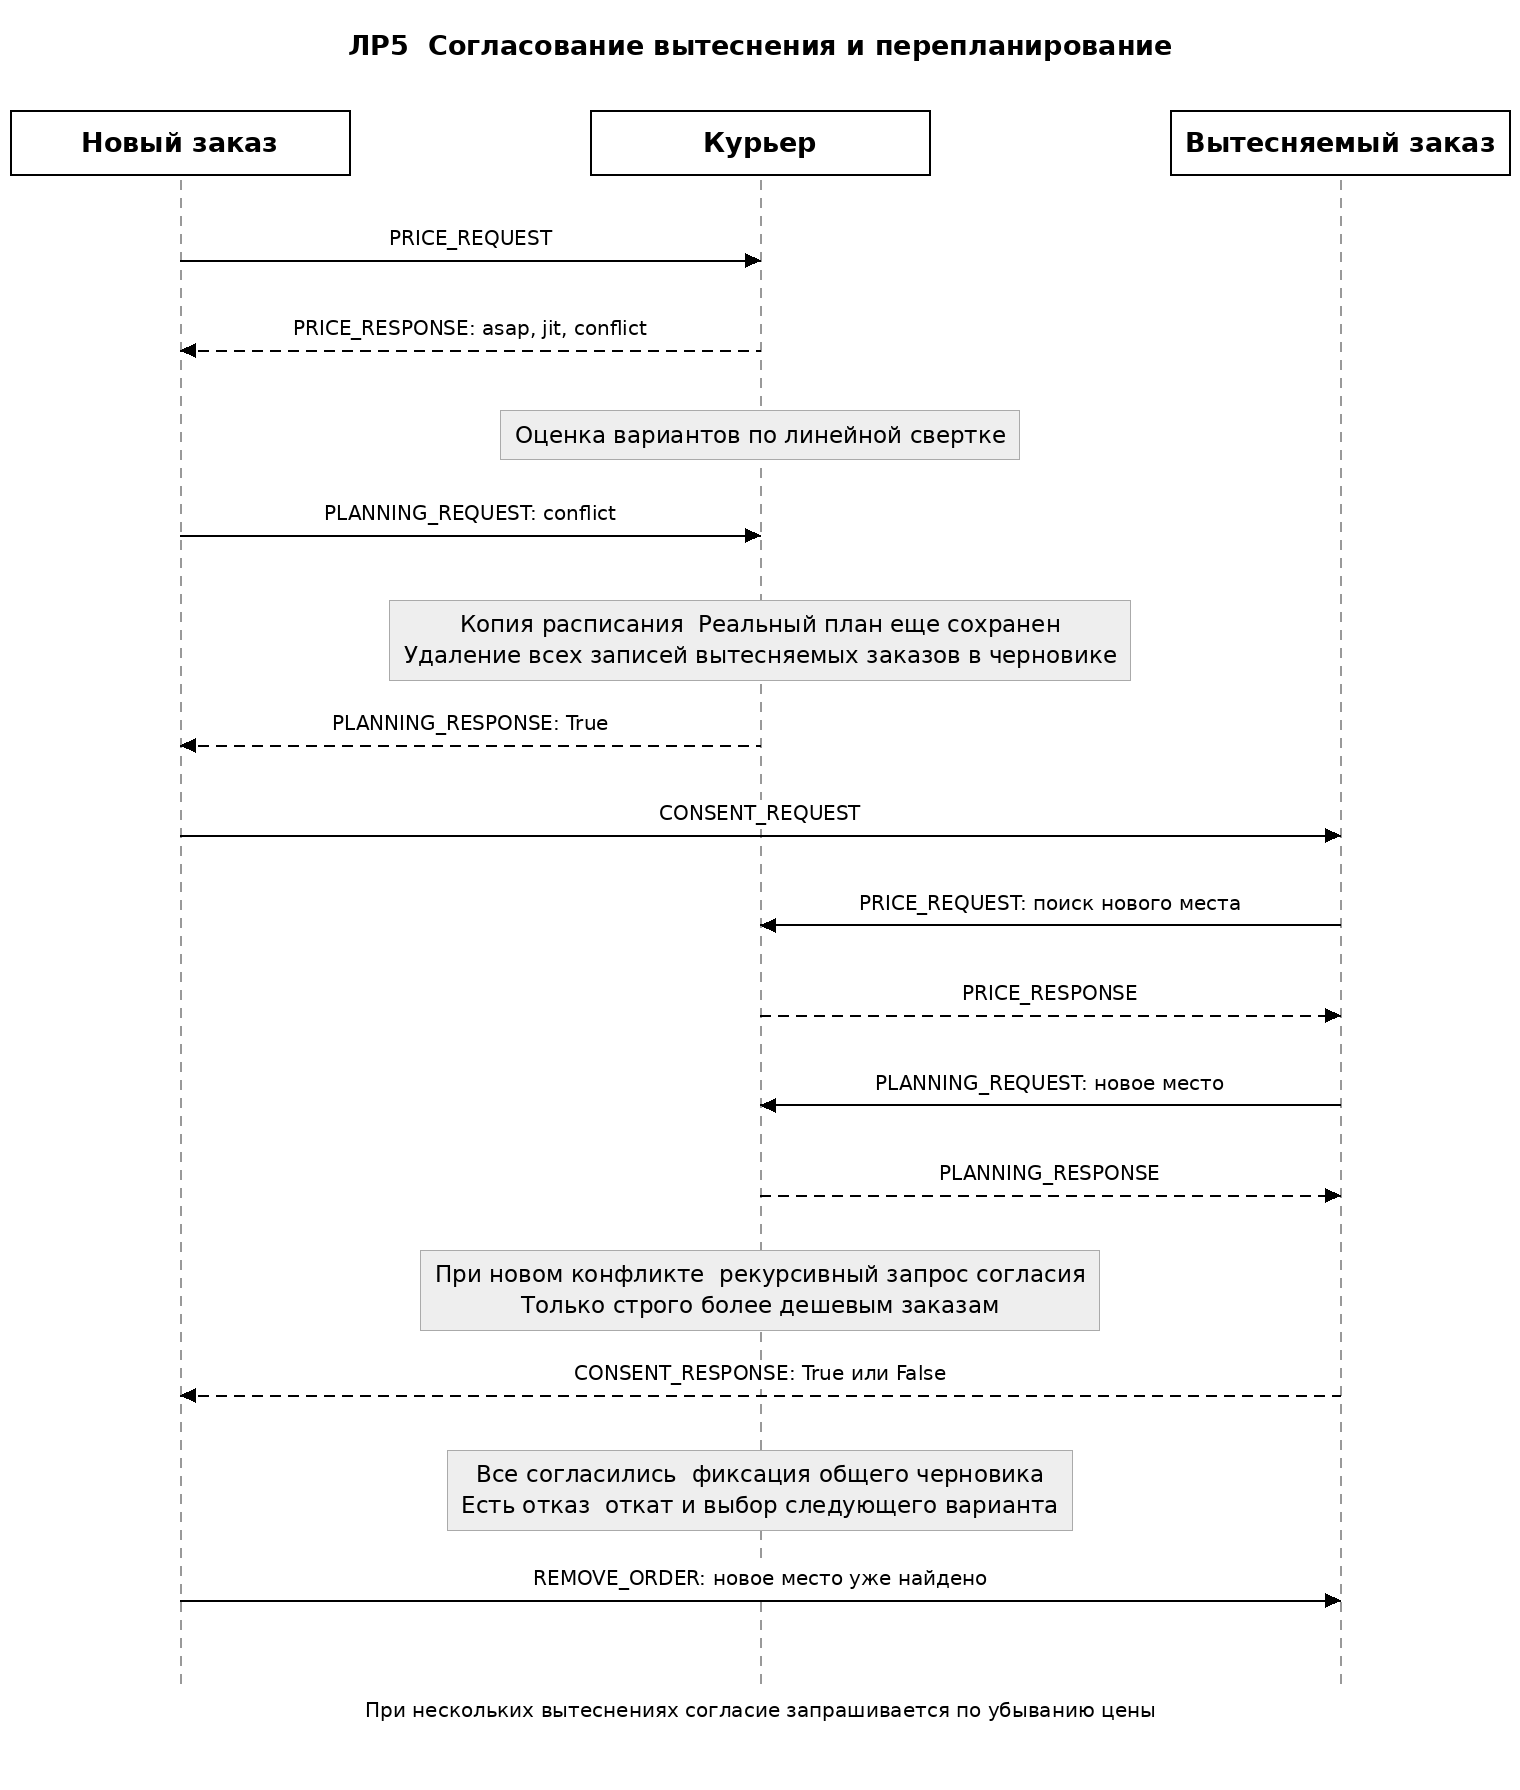

## 8 Самостоятельная работа

Небольшие демонстрации: 1) включение `multiple=True` дает одновременное вытеснение двух заказов; 2) сокращение срока заказа 2 до 5 вызывает отказ уступить и откат; 3) отдельные маршруты создают цепочку «документы → заказ 1 → заказ 2». В последнем примере глубина переговоров равна 2. Это демонстрации заданий, а не нагрузочные испытания. Результаты сохраняются в Самостоятельная_ЛР5.json.

In [21]:
level = logging.getLogger().level
demo_handler = logging.FileHandler('Отчёты/Переговоры_самостоятельная_ЛР5.txt', encoding='utf-8', mode='w')
root_logger = logging.getLogger()
main_handlers = list(root_logger.handlers)
root_logger.handlers = [demo_handler]
try:
    demonstrations = run_demonstrations()
finally:
    root_logger.handlers = main_handlers
    demo_handler.close()
print(json.dumps(demonstrations, ensure_ascii=False, indent=2))


Несколько заказов {'Сообщений': 33, 'Вытеснений': 3, 'Отказов уступить': 0, 'Глубина переговоров': 1, 'Максимум вытесненных за раз': 2}
Отказ уступить {'Сообщений': 18, 'Вытеснений': 0, 'Отказов уступить': 1, 'Глубина переговоров': 1, 'Максимум вытесненных за раз': 0}
Рекурсивные переговоры {'Сообщений': 26, 'Вытеснений': 2, 'Отказов уступить': 0, 'Глубина переговоров': 2, 'Максимум вытесненных за раз': 1}
{
  "Несколько заказов": {
    "Сообщений": 33,
    "Вытеснений": 3,
    "Отказов уступить": 0,
    "Глубина переговоров": 1,
    "Максимум вытесненных за раз": 2
  },
  "Отказ уступить": {
    "Сообщений": 18,
    "Вытеснений": 0,
    "Отказов уступить": 1,
    "Глубина переговоров": 1,
    "Максимум вытесненных за раз": 0
  },
  "Рекурсивные переговоры": {
    "Сообщений": 26,
    "Вытеснений": 2,
    "Отказов уступить": 0,
    "Глубина переговоров": 2,
    "Максимум вытесненных за раз": 1
  }
}


В групповом примере максимальный размер одновременного вытеснения — **2**. В примере отказа — **1 отказ и 0 выполненных вытеснений**. В рекурсивном примере — **2 вытеснения и глубина 2**. Строгое сравнение цен ограничивает цепочки, но не обеспечивает глобальную оптимальность. Бюджет и компенсационные выплаты не реализуются.

## 9 Ответы на контрольные вопросы

**1 Какие конфликты могут возникать в расписании**

Заказы могут претендовать на один интервал одного курьера, превышать его ограничения по типу, массе или объему, нарушать желаемые сроки. В ЛР5 разбирается пересечение действий курьера по времени. Ожидание и записи нулевой длительности не считаются занятым интервалом.

**2 Как разрешать конфликты заказов и ресурсов**

Можно выбрать другого курьера, другое время, перенести заказ в хвост или вытеснить менее дорогой заказ. Здесь новый заказ оценивает вариант conflict, а уступающий сначала ищет новое место и дает согласие. Возможны несколько уступающих заказов и рекурсивная цепочка переговоров.

**3 Зачем быстро строить первое расписание**

Первый допустимый план уже позволяет начать работу и дает базу для последующего улучшения. Полный перебор перестановок до получения первого результата может занять слишком много времени. Затем локальные переговоры пересматривают наиболее неудобные назначения.

**4 Каковы условия останова**

В этой реализации каждый агент перебирает конечный список предложений. В рекурсивной цепочке цена вытесняемого заказа строго меньше цены вытесняющего, предки цепочки исключаются. При отсутствии нового места возвращается отказ и выполняется откат. После обработки всех запросов обмен завершается. Это остановка учебного протокола, а не доказательство конкурентного равновесия.

**5 Преимущества и ограничения распределенных алгоритмов**

Агенты принимают локальные решения и могут перестраивать уже существующий план. Однако результат зависит от порядка запросов, возможны лишние переговоры и локальные оптимумы. Согласование, копии состояния, предотвращение циклов и более содержательные критерии улучшают надежность; глобальная оптимальность ими не гарантируется.

**6 Зачем нужна копия расписания**

После удаления старых записей вставка нового заказа или переезд одного из уступающих могут оказаться невозможными. Копия позволяет вернуть все расписания и назначения к состоянию до попытки. В коде используется общий черновик: реальные расписания меняются только после согласия всех участников.

**7 Чем вытеснение отличается от метода компенсаций**

Решение о допустимости вытеснения основано на сравнении цен заказов, а не на бюджете и полной функции удовлетворенности. Уступающий не получает компенсационную выплату. Добавленные согласие и рекурсивные переезды сами по себе не реализуют метод компенсаций Виттиха–Скобелева и не обеспечивают рыночное равновесие.

## Вывод

Система обнаруживает конфликты, формирует вариант вытеснения и перепланирует уступающих. Согласование и общий черновик предотвращают потерю старого размещения при неудачном переезде. Выполнены все три самостоятельных задания. В собственном сценарии стоимость уменьшилась с 50 до 40. В исходном проекте нет эталонного конфликтного Excel и коммита 2e6813e. Поэтому создан собственный сценарий с одним Лермонтовым М. Ю. и скоростью 5. Числа 129,45 и 108,65 относятся к данным эталона и здесь не воспроизводятся; результаты собственного сценария не выдаются за эталонные.